In [1]:
import sys

import matplotlib
import numpy
import pandas
import scipy
import sklearn

print(
    sys.version.split()[0],
    numpy.__version__,
    pandas.__version__,
    scipy.__version__,
    sklearn.__version__,
    matplotlib.__version__,
)

3.12.14 2.3.4 2.3.3 1.16.3 1.7.2 3.10.7


In [2]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

SEED = 3246

df = pd.read_csv("data/drybean.csv")
class_label = df.pop("Class").to_numpy()  # Reserved for the evaluation in Part 6.
X = df.to_numpy(dtype=float)
features = list(df.columns)
n = len(X)
print(X.shape, "missing values:", int(np.isnan(X).sum()))

(13543, 16) missing values: 0


In [3]:
Xs = StandardScaler().fit_transform(X)

**Seed.** `SEED = 3246`, the last four digits of my student ID.

## Part 1 - Audit of the data

In [4]:
feature_variances = df.var(ddof=0)
variance_shares = feature_variances / feature_variances.sum()

feature_audit = pd.DataFrame({
    "Mean": df.mean(),
    "Std (ddof=0)": df.std(ddof=0),
    "Min": df.min(),
    "Max": df.max(),
    "Share of total variance": variance_shares,
})

print(feature_audit.to_string(
    float_format=lambda value: f"{value:.4g}",
    formatters={"Share of total variance": lambda share: f"{100 * share:.4g}%"},
))

top_variance_features = variance_shares.nlargest(2)
print(f"Combined variance share of the two largest contributors: {top_variance_features.sum():.4%}")

                     Mean  Std (ddof=0)       Min       Max Share of total variance
Area            5.305e+04     2.939e+04 2.042e+04 2.546e+05                  49.24%
Perimeter             855         214.7     524.7      1985               0.002628%
MajorAxisLength     319.9         85.81     183.6     738.9              0.0004196%
MinorAxisLength     202.4         45.05     122.5     460.2              0.0001157%
AspectRatio         1.581        0.2452     1.025      2.43              3.428e-09%
Eccentricity       0.7503       0.09185     0.219    0.9114              4.809e-10%
ConvexArea      5.377e+04     2.984e+04 2.068e+04 2.633e+05                  50.76%
EquivDiameter         253         59.31     161.2     569.4              0.0002005%
Extent             0.7498       0.04894    0.5553    0.8662              1.365e-10%
Solidity           0.9872       0.00465    0.9192    0.9947              1.232e-12%
Roundness          0.8737       0.05939    0.4896    0.9907               2.

ConvexArea (50.7610%) and Area (49.2357%) together account for 99.9966% of the total variance on the original scales. Their large spread means differences in these two measurements can dominate Euclidean distances between grains before scaling.

In [5]:
pearson = df.corr(method="pearson").to_numpy()
first, second = np.triu_indices(len(features), k=1)
pair_correlations = pearson[first, second]
strong = np.abs(pair_correlations) > 0.95

strong_pairs = pd.DataFrame({
    "Feature 1": df.columns[first[strong]],
    "Feature 2": df.columns[second[strong]],
    "Pearson r": pair_correlations[strong],
})

print(f"Pairs with |Pearson r| > 0.95: {len(strong_pairs)}")
print(strong_pairs.to_string(index=False, float_format=lambda value: f"{value:.5f}"))

Pairs with |Pearson r| > 0.95: 15
      Feature 1       Feature 2  Pearson r
           Area       Perimeter    0.96691
           Area MinorAxisLength    0.95204
           Area      ConvexArea    0.99994
           Area   EquivDiameter    0.98500
      Perimeter MajorAxisLength    0.97756
      Perimeter      ConvexArea    0.96787
      Perimeter   EquivDiameter    0.99145
MajorAxisLength   EquivDiameter    0.96227
MinorAxisLength      ConvexArea    0.95178
    AspectRatio     Compactness   -0.98764
    AspectRatio    ShapeFactor3   -0.97853
   Eccentricity     Compactness   -0.97031
   Eccentricity    ShapeFactor3   -0.98106
     ConvexArea   EquivDiameter    0.98526
    Compactness    ShapeFactor3    0.99868


There are 15 pairs with an absolute Pearson correlation above 0.95. For example, Area and ConvexArea have a Pearson correlation of +0.99994. Area measures the grain silhouette and ConvexArea measures its convex hull, which fills in indentations. Larger grains generally have larger areas under both measurements.

## Part 2 - K-Means by hand and the effect of scaling

In [6]:
def lloyd_kmeans(X, init_centers, max_iter=300):
    """Return (labels, centers, inertia, n_iter)."""
    if max_iter < 1:
        raise ValueError("max_iter must be at least 1.")

    X = np.asarray(X, dtype=float)
    centers = np.array(init_centers, dtype=float, copy=True)
    labels = None

    for n_iter in range(1, max_iter + 1):
        previous_labels = labels
        differences = X[:, None, :] - centers[None, :, :]
        squared_distances = np.sum(differences ** 2, axis=2)
        labels = np.argmin(squared_distances, axis=1)

        for cluster in range(len(centers)):
            members = X[labels == cluster]
            if len(members):
                centers[cluster] = members.mean(axis=0)

        if previous_labels is not None and np.array_equal(labels, previous_labels):
            break

    residuals = X - centers[labels]
    inertia = float(np.sum(residuals ** 2))
    return labels, centers, inertia, n_iter

In [7]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

kmeans_clusters = 7
init = Xs[np.random.default_rng(SEED).choice(n, kmeans_clusters, replace=False)]
lloyd_labels, lloyd_centers, lloyd_inertia, lloyd_iterations = lloyd_kmeans(Xs, init)

reference_kmeans = KMeans(
    n_clusters=kmeans_clusters,
    init=init,
    n_init=1,
    algorithm="lloyd",
    tol=0.0,
    max_iter=300,
).fit(Xs)

labels_match = np.array_equal(lloyd_labels, reference_kmeans.labels_)
centers_match = np.allclose(
    lloyd_centers, reference_kmeans.cluster_centers_, rtol=1e-6, atol=0.0
)
inertia_match = np.isclose(lloyd_inertia, reference_kmeans.inertia_, rtol=1e-6, atol=0.0)

print(f"Identical labels: {labels_match}")
print(f"Centers match at rtol=1e-6: {centers_match}")
print(f"Inertia matches at rtol=1e-6: {inertia_match}")
print(f"Inertia (manual / scikit-learn): {lloyd_inertia:.6f} / {reference_kmeans.inertia_:.6f}")
print(f"Assignment steps (manual / scikit-learn): {lloyd_iterations} / {reference_kmeans.n_iter_}")

Identical labels: True
Centers match at rtol=1e-6: True
Inertia matches at rtol=1e-6: True
Inertia (manual / scikit-learn): 48671.543748 / 48671.543748
Assignment steps (manual / scikit-learn): 23 / 23


In [8]:
kmeans_raw = KMeans(n_clusters=kmeans_clusters, n_init=10, random_state=SEED).fit(X)
kmeans_scaled = KMeans(n_clusters=kmeans_clusters, n_init=10, random_state=SEED).fit(Xs)

area_index = features.index("Area")
area_labels = KMeans(n_clusters=kmeans_clusters, n_init=10, random_state=SEED).fit_predict(
    X[:, [area_index]]
)

scaling_results = []
for space, data, model in (
    ("Raw", X, kmeans_raw),
    ("Standardized", Xs, kmeans_scaled),
):
    sizes = sorted(np.bincount(model.labels_, minlength=kmeans_clusters), reverse=True)
    scaling_results.append({
        "Feature space": space,
        "Inertia": model.inertia_,
        "Silhouette": silhouette_score(
            data, model.labels_, sample_size=4000, random_state=SEED
        ),
        "Cluster sizes (largest first)": ", ".join(map(str, sizes)),
        "ARI vs Area only": adjusted_rand_score(model.labels_, area_labels),
    })

scaling_comparison = pd.DataFrame(scaling_results).set_index("Feature space")
print(scaling_comparison.to_string(formatters={
    "Inertia": "{:.8g}".format,
    "Silhouette": "{:.6f}".format,
    "ARI vs Area only": "{:.6f}".format,
}))

                    Inertia Silhouette           Cluster sizes (largest first) ARI vs Area only
Feature space                                                                                  
Raw           6.1243766e+11   0.539499  4235, 3238, 2531, 1910, 1109, 303, 217         0.989310
Standardized      48671.457   0.309617  3158, 3112, 2479, 2033, 1702, 539, 520         0.391541


The raw fit has a higher silhouette (0.5395 vs. 0.3096), which shows stronger separation in its own distance space. The raw partition has an ARI of 0.9893 with the Area-only partition, compared with 0.3915 after standardization. Area and ConvexArea contribute 99.9966% of raw variance in Part 1 and have a Pearson correlation of +0.99994, so raw Euclidean distances are dominated by two measurements of grain size. I will use the standardized features for subsequent clustering so shape measurements can contribute on the same scale as size measurements.

## Part 3 - How many clusters?

      Inertia Silhouette
k                       
2  129,194.04   0.402129
3   94,331.74   0.406817
4   75,993.19   0.345023
5   61,624.65   0.358333
6   54,900.75   0.357269
7   48,671.46   0.309617
8   45,083.24   0.303606
9   41,904.83   0.303208
10  39,708.71   0.269014
Highest silhouette: k = 3


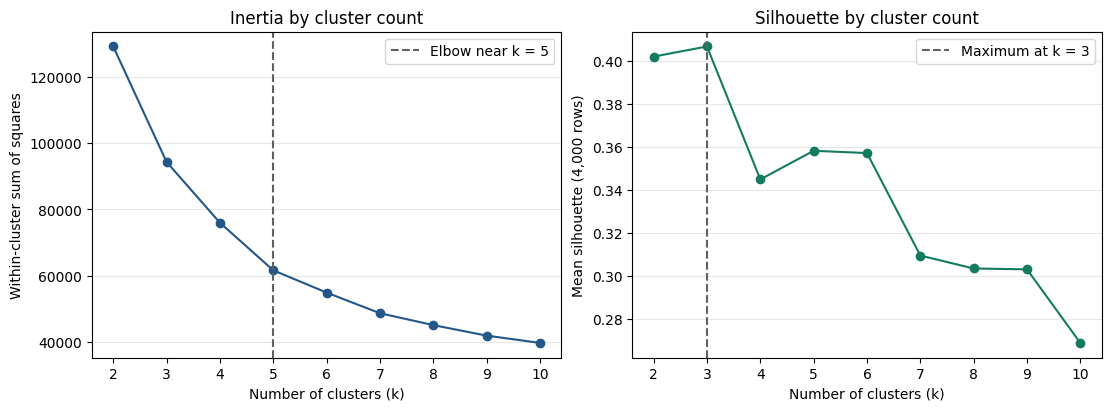

In [9]:
%matplotlib inline
import matplotlib.pyplot as plt

k_results = []
for k in range(2, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Xs)
    k_results.append({
        "k": k,
        "Inertia": model.inertia_,
        "Silhouette": silhouette_score(
            Xs, model.labels_, sample_size=4000, random_state=SEED
        ),
    })

k_comparison = pd.DataFrame(k_results).set_index("k")
best_silhouette_k = int(k_comparison["Silhouette"].idxmax())
print(k_comparison.to_string(formatters={
    "Inertia": "{:,.2f}".format,
    "Silhouette": "{:.6f}".format,
}))
print(f"Highest silhouette: k = {best_silhouette_k}")

fig, (inertia_ax, silhouette_ax) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
inertia_ax.plot(k_comparison.index, k_comparison["Inertia"], "o-", color="#235789")
inertia_ax.axvline(5, linestyle="--", color="#606060", label="Elbow near k = 5")
inertia_ax.set_title("Inertia by cluster count")
inertia_ax.set_ylabel("Within-cluster sum of squares")

silhouette_ax.plot(k_comparison.index, k_comparison["Silhouette"], "o-", color="#137b60")
silhouette_ax.axvline(
    best_silhouette_k, linestyle="--", color="#606060",
    label=f"Maximum at k = {best_silhouette_k}",
)
silhouette_ax.set_title("Silhouette by cluster count")
silhouette_ax.set_ylabel("Mean silhouette (4,000 rows)")

for ax in (inertia_ax, silhouette_ax):
    ax.set_xlabel("Number of clusters (k)")
    ax.set_xticks(k_comparison.index)
    ax.grid(axis="y", alpha=0.3)
    ax.legend()

plt.show()

The highest silhouette is 0.406817 at k = 3. I read the inertia elbow around k = 5: inertia falls by about 14,369 from k = 4 to k = 5, then by 6,724 from k = 5 to k = 6 and by less at each later step.

In [10]:
from itertools import combinations

single_start_runs = [
    KMeans(n_clusters=7, n_init=1, random_state=SEED + i).fit(Xs)
    for i in range(10)
]
pairwise_ari = [
    adjusted_rand_score(first.labels_, second.labels_)
    for first, second in combinations(single_start_runs, 2)
]
single_start_inertias = [run.inertia_ for run in single_start_runs]

print(f"Pairs of runs: {len(pairwise_ari)}")
print(f"Mean pairwise ARI: {np.mean(pairwise_ari):.6f}")
print(f"Minimum pairwise ARI: {min(pairwise_ari):.6f}")
print(f"Minimum inertia: {min(single_start_inertias):,.2f}")
print(f"Maximum inertia: {max(single_start_inertias):,.2f}")

Pairs of runs: 45
Mean pairwise ARI: 0.731287
Minimum pairwise ARI: 0.485477
Minimum inertia: 48,671.46
Maximum inertia: 54,155.90


At k = 7, the 45 pairs of single-start runs had a mean ARI of 0.7313 and a minimum of 0.4855. Inertia ranged from 48,671.46 to 54,155.90. The differences in both the assignments and inertia support keeping n_init = 10 so K-Means can select the lowest-inertia fit across several starts.

**Recommendation: k = 3.** It gives the best silhouette (0.4068), compared with 0.3583 at the elbow near k = 5 and 0.3096 at k = 7. The elbow gives a case for five finer groups, but I would choose three for their stronger separation. The variation across starts at k = 7 also makes that solution less convincing as a default. Parts 4 to 6 use k = 7 as specified in the assignment.

## Part 4 - Hierarchical clustering on a subsample

I draw 2,000 rows without replacement using the student seed. A full float64 matrix of pairwise distances would take about 1.47 GB for all 13,543 rows, compared with 32 MB for the subsample.

In [11]:
from scipy.cluster.hierarchy import cophenet, dendrogram, fcluster, linkage
from scipy.spatial.distance import pdist
from sklearn.cluster import AgglomerativeClustering

sub_idx = np.random.default_rng(SEED).choice(n, 2000, replace=False)
Xsub = Xs[sub_idx]
subsample_distances = pdist(Xsub)
kmeans_sub_labels = kmeans_scaled.labels_[sub_idx]
print(f"Subsample: {Xsub.shape[0]:,} rows, {Xsub.shape[1]} standardized features")

hierarchical_labels = {}
linkage_trees = {}
linkage_results = []
for method in ("ward", "complete", "average", "single"):
    tree = linkage(Xsub, method=method)
    labels = AgglomerativeClustering(n_clusters=7, linkage=method).fit_predict(Xsub)
    linkage_trees[method] = tree
    hierarchical_labels[method] = labels
    linkage_results.append({
        "Linkage": method,
        "Cophenetic correlation": cophenet(tree, subsample_distances)[0],
        "Largest cluster share": np.bincount(labels).max() / len(labels),
        "ARI vs K-Means on the same rows": adjusted_rand_score(kmeans_sub_labels, labels),
    })

linkage_comparison = pd.DataFrame(linkage_results).set_index("Linkage")
print(linkage_comparison.to_string(formatters={
    "Cophenetic correlation": "{:.6f}".format,
    "Largest cluster share": "{:.2%}".format,
    "ARI vs K-Means on the same rows": "{:.6f}".format,
}))

Subsample: 2,000 rows, 16 standardized features


         Cophenetic correlation Largest cluster share ARI vs K-Means on the same rows
Linkage                                                                              
ward                   0.599913                22.65%                        0.726889
complete               0.769340                48.20%                        0.470054
average                0.838452                94.35%                        0.044933
single                 0.725018                99.60%                        0.002272


Cut height: 36.2668 (7 clusters)


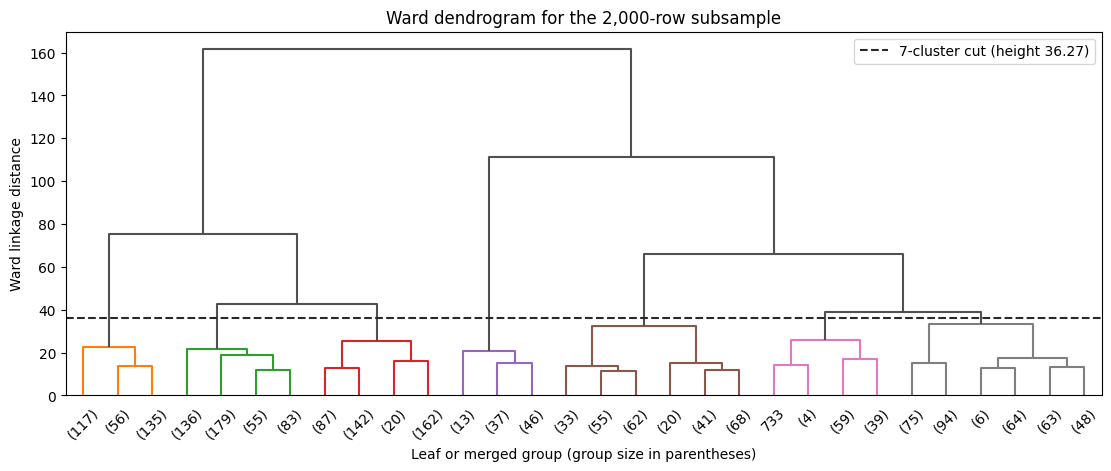

In [12]:
selected_linkage = "ward"
selected_tree = linkage_trees[selected_linkage]
cut_height = (selected_tree[-7, 2] + selected_tree[-6, 2]) / 2
cut_labels = fcluster(selected_tree, t=cut_height, criterion="distance")
print(f"Cut height: {cut_height:.4f} ({np.unique(cut_labels).size} clusters)")

fig, ax = plt.subplots(figsize=(11, 4.6), layout="constrained")
dendrogram(
    selected_tree, truncate_mode="lastp", p=30,
    color_threshold=cut_height, above_threshold_color="#505050",
    leaf_rotation=45, ax=ax,
)
ax.axhline(
    cut_height, color="#292929", linestyle="--",
    label=f"7-cluster cut (height {cut_height:.2f})",
)
ax.set_title("Ward dendrogram for the 2,000-row subsample")
ax.set_xlabel("Leaf or merged group (group size in parentheses)")
ax.set_ylabel("Ward linkage distance")
ax.legend()
plt.show()

Average and single linkage show chaining: the largest group holds 94.35% and 99.60% of the subsample, respectively. Average has the highest cophenetic correlation (0.8385), which reflects how well its tree preserves the original distances. I would use Ward for the seven-cluster partition because its largest group holds 22.65% of the sample and it has the highest agreement with the standardized K-Means partition on the same rows (ARI 0.7269).

## Part 5 - DBSCAN

In [13]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

def k_distances(X, min_samples):
    """Return the n k-distances in ascending order."""
    neighbors = NearestNeighbors(n_neighbors=min_samples, algorithm="kd_tree").fit(X)
    # Explicitly query the training points so each point counts as a neighbor.
    distances, _ = neighbors.kneighbors(X)
    return np.sort(distances[:, -1])

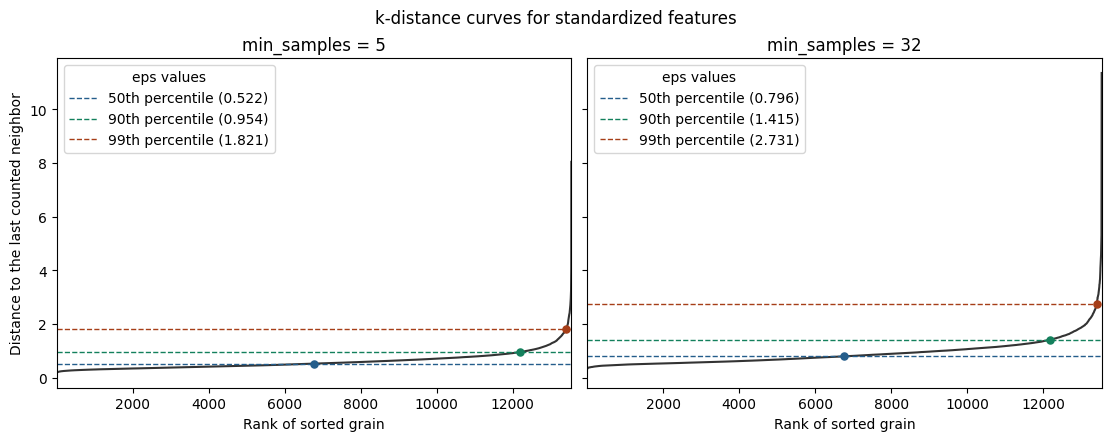

min_samples = 5: 89.995% are core points at the 90th percentile.
min_samples = 32: 89.995% are core points at the 90th percentile.


In [14]:
min_samples_values = (5, 32)
eps_percentiles = (50, 90, 99)
k_distance_curves = {
    min_samples: k_distances(Xs, min_samples)
    for min_samples in min_samples_values
}
eps_values = {
    (min_samples, percentile): float(np.quantile(curve, percentile / 100))
    for min_samples, curve in k_distance_curves.items()
    for percentile in eps_percentiles
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True, layout="constrained")
percentile_colors = ("#245d8b", "#13805c", "#a63e18")
for ax, (min_samples, curve) in zip(axes, k_distance_curves.items()):
    ranks = np.arange(1, len(curve) + 1)
    ax.plot(ranks, curve, color="#333333", linewidth=1.5)
    for percentile, color in zip(eps_percentiles, percentile_colors):
        eps = eps_values[min_samples, percentile]
        rank_at_percentile = 1 + (len(curve) - 1) * percentile / 100
        ax.axhline(
            eps, color=color, linestyle="--", linewidth=1,
            label=f"{percentile}th percentile ({eps:.3f})",
        )
        ax.scatter(rank_at_percentile, eps, color=color, s=26, zorder=3)
    ax.set_title(f"min_samples = {min_samples}")
    ax.set_xlabel("Rank of sorted grain")
    ax.set_xlim(1, len(curve))
    ax.legend(loc="upper left", title="eps values")

axes[0].set_ylabel("Distance to the last counted neighbor")
fig.suptitle("k-distance curves for standardized features")
plt.show()

for min_samples, curve in k_distance_curves.items():
    share_at_90 = np.mean(curve <= eps_values[min_samples, 90])
    print(f"min_samples = {min_samples}: {share_at_90:.3%} are core points at the 90th percentile.")

The curves rise gradually before the upper tail, with no clear bend to choose a single eps. At the 90th percentile about 90% of the grains are core points (89.995% for both settings), because their k-distance is at most eps. Each of those grains therefore has at least min_samples neighbors inside the radius, counting itself.

In [15]:
dbscan_labels = {}
dbscan_results = []
for (min_samples, percentile), eps in eps_values.items():
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(Xs)
    dbscan_labels[min_samples, percentile] = labels
    non_noise = labels != -1
    non_noise_labels = labels[non_noise]
    _, sizes = np.unique(non_noise_labels, return_counts=True)
    non_noise_count = len(non_noise_labels)
    largest_share = sizes.max() / non_noise_count if non_noise_count else np.nan
    silhouette = np.nan
    if len(sizes) >= 2:
        silhouette = silhouette_score(
            Xs[non_noise], non_noise_labels,
            sample_size=min(4000, non_noise_count), random_state=SEED,
        )
    dbscan_results.append({
        "min_samples": min_samples,
        "Percentile": percentile,
        "eps": eps,
        "Clusters": len(sizes),
        "Noise share": 1 - non_noise.mean(),
        "Largest share of non-noise": largest_share,
        "Non-noise silhouette": silhouette,
    })

dbscan_comparison = pd.DataFrame(dbscan_results)
print(dbscan_comparison.to_string(index=False, na_rep="", formatters={
    "eps": "{:.6f}".format,
    "Noise share": "{:.2%}".format,
    "Largest share of non-noise": "{:.2%}".format,
    "Non-noise silhouette": "{:.6f}".format,
}))

 min_samples  Percentile      eps  Clusters Noise share Largest share of non-noise Non-noise silhouette
           5          50 0.522270        58      40.12%                     84.70%            -0.227438
           5          90 0.953973         6       6.23%                     96.86%             0.203922
           5          99 1.820672         1       0.51%                    100.00%                     
          32          50 0.796162         4      32.90%                     83.10%             0.371986
          32          90 1.415288         2       3.70%                     96.88%             0.570351
          32          99 2.730673         1       0.25%                    100.00%                     


As eps increases, the number of clusters drops from 58 to 6 to 1 for min_samples = 5 and from 4 to 2 to 1 for min_samples = 32. The noise share falls from 40.12% to 0.51% and from 32.90% to 0.25%, respectively. None of the six settings gives a useful partition of the full dataset. At the lower percentile many grains are discarded as noise, while at the 99th percentile every retained grain belongs to one cluster. The highest non-noise silhouette is 0.5704 at min_samples = 32 and the 90th percentile, even though 96.88% of the retained grains sit in one cluster and 3.70% of all grains are excluded from the score. The silhouette only describes the retained points, so I read it alongside the noise share and cluster sizes.

## Part 6 - PCA and comparison with the varieties

In [16]:
def pca_eig(X):
    """Return (explained_variance, components) with one component per row."""
    X = np.asarray(X, dtype=float)
    centered = X - X.mean(axis=0)
    covariance = centered.T @ centered / (len(X) - 1)
    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
    explained_variance = eigenvalues[::-1]
    components = eigenvectors[:, ::-1].T

    largest_entries = np.argmax(np.abs(components), axis=1)
    pivots = components[np.arange(len(components)), largest_entries]
    signs = np.where(pivots < 0, -1.0, 1.0)
    return explained_variance, components * signs[:, None]

In [17]:
from sklearn.decomposition import PCA

explained_variance, components = pca_eig(Xs)
reference_pca = PCA().fit(Xs)
reference_signs = np.where(
    np.sum(components * reference_pca.components_, axis=1) < 0, -1.0, 1.0
)
aligned_components = reference_pca.components_ * reference_signs[:, None]

eigenvalues_match = np.allclose(
    explained_variance, reference_pca.explained_variance_, rtol=1e-6, atol=0.0
)
components_match = np.allclose(components, aligned_components, rtol=1e-6, atol=0.0)
print(f"Eigenvalues match scikit-learn: {eigenvalues_match}")
print(f"Components match up to sign: {components_match}")

variance_ratio = explained_variance / explained_variance.sum()
cumulative_variance = np.cumsum(variance_ratio)
m = int(np.searchsorted(cumulative_variance, 0.95, side="left") + 1)
variance_summary = pd.DataFrame({
    "Eigenvalue": explained_variance[:6],
    "Explained variance share": variance_ratio[:6],
    "Cumulative variance share": cumulative_variance[:6],
}, index=pd.Index([f"PC{i}" for i in range(1, 7)], name="Component"))
print(variance_summary.to_string(float_format="{:.6f}".format))
print(f"Minimum components for at least 95%: m = {m} (share {cumulative_variance[m - 1]:.6f})")

Eigenvalues match scikit-learn: True
Components match up to sign: True
           Eigenvalue  Explained variance share  Cumulative variance share
Component                                                                 
PC1          8.888146                  0.555468                   0.555468
PC2          4.218038                  0.263608                   0.819076
PC3          1.277599                  0.079844                   0.898920
PC4          0.817410                  0.051084                   0.950004
PC5          0.440529                  0.027531                   0.977535
PC6          0.184361                  0.011522                   0.989057
Minimum components for at least 95%: m = 4 (share 0.950004)


In [18]:
loading_rows = []
for number, component in enumerate(components[:2], start=1):
    strongest = np.argsort(-np.abs(component), kind="stable")[:3]
    for index in strongest:
        loading_rows.append({
            "Component": f"PC{number}",
            "Feature": features[index],
            "Loading": component[index],
        })

pca_loadings = pd.DataFrame(loading_rows)
print(pca_loadings.to_string(index=False, formatters={"Loading": "{:+.6f}".format}))

Component         Feature   Loading
      PC1 MajorAxisLength +0.325547
      PC1    ShapeFactor2 -0.314490
      PC1       Perimeter +0.310728
      PC2 MinorAxisLength +0.342766
      PC2    ShapeFactor1 -0.331880
      PC2     AspectRatio -0.331065


PC1 looks like a grain-size axis, with positive weights on MajorAxisLength (+0.3255) and Perimeter (+0.3107) and a negative weight on ShapeFactor2 (-0.3145).

PC2 distinguishes wider, less elongated grains, with a positive loading on MinorAxisLength (+0.3428) and negative loadings on ShapeFactor1 (-0.3319) and AspectRatio (-0.3311).

Silhouettes for K-Means on PCA scores


2 components: 0.433357


4 components: 0.327851


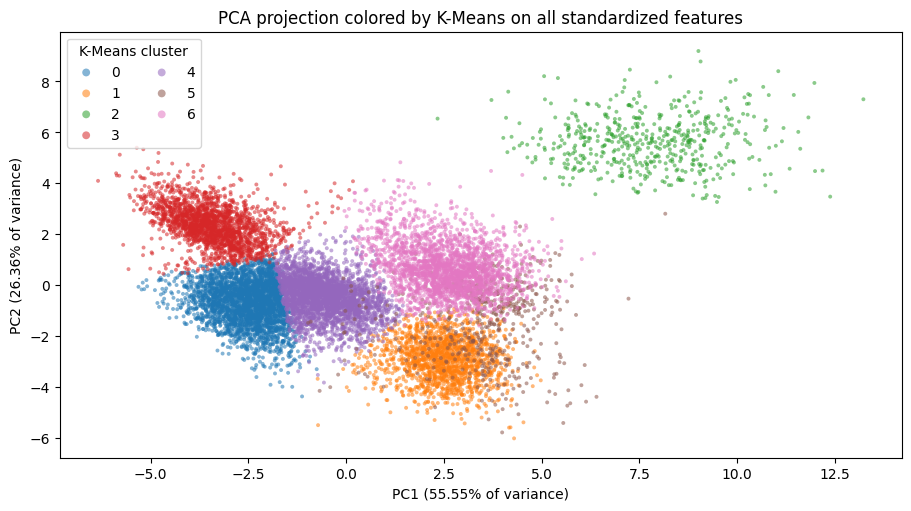

In [19]:
scores = (Xs - Xs.mean(axis=0)) @ components.T
scores_2 = scores[:, :2]
scores_m = scores[:, :m]
kmeans_pca_2 = KMeans(n_clusters=7, n_init=10, random_state=SEED).fit(scores_2)
kmeans_pca_m = KMeans(n_clusters=7, n_init=10, random_state=SEED).fit(scores_m)

print("Silhouettes for K-Means on PCA scores")
for count, projection, model in ((2, scores_2, kmeans_pca_2), (m, scores_m, kmeans_pca_m)):
    score = silhouette_score(projection, model.labels_, sample_size=4000, random_state=SEED)
    print(f"{count} components: {score:.6f}")

fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
full_space_labels = kmeans_scaled.labels_
colors = plt.get_cmap("tab10")
for cluster in np.unique(full_space_labels):
    members = full_space_labels == cluster
    ax.scatter(
        scores_2[members, 0], scores_2[members, 1],
        s=8, alpha=0.55, color=colors(cluster), edgecolors="none", label=str(cluster),
    )

ax.set_title("PCA projection colored by K-Means on all standardized features")
ax.set_xlabel(f"PC1 ({variance_ratio[0]:.2%} of variance)")
ax.set_ylabel(f"PC2 ({variance_ratio[1]:.2%} of variance)")
ax.legend(title="K-Means cluster", ncols=2, markerscale=2)
plt.show()

### Evaluation against the recorded varieties

The settings and cluster assignments above were established before using the variety labels. Ward is evaluated on its 2,000 selected rows, and the other methods on all 13,543 rows. Ward's scores therefore describe a different sample. For the DBSCAN scores, all noise points share the additional label -1.

In [20]:
from sklearn.metrics import normalized_mutual_info_score

methods = [
    ("K-Means on raw features", class_label, kmeans_raw.labels_),
    ("K-Means on standardized features", class_label, kmeans_scaled.labels_),
    ("K-Means on 2 PCs", class_label, kmeans_pca_2.labels_),
    (f"K-Means on {m} PCs", class_label, kmeans_pca_m.labels_),
    ("Ward on the subsample", class_label[sub_idx], hierarchical_labels["ward"]),
    ("DBSCAN (min_samples=5, p50)", class_label, dbscan_labels[5, 50]),
    ("DBSCAN (min_samples=5, p90)", class_label, dbscan_labels[5, 90]),
]
variety_comparison = pd.DataFrame([
    {
        "Method": name,
        "Rows scored": len(varieties),
        "ARI": adjusted_rand_score(varieties, labels),
        "NMI": normalized_mutual_info_score(varieties, labels),
    }
    for name, varieties, labels in methods
])
print(variety_comparison.to_string(index=False, float_format="{:.6f}".format))

variety_by_cluster = pd.crosstab(
    class_label, kmeans_scaled.labels_, rownames=["Variety"], colnames=["K-Means cluster"]
)
print("\nVariety by K-Means cluster on all standardized features")
print(variety_by_cluster.to_string())

                          Method  Rows scored      ARI      NMI
         K-Means on raw features        13543 0.377996 0.514500
K-Means on standardized features        13543 0.666950 0.712434
                K-Means on 2 PCs        13543 0.688022 0.726286
                K-Means on 4 PCs        13543 0.657988 0.701758
           Ward on the subsample         2000 0.689914 0.736640
     DBSCAN (min_samples=5, p50)        13543 0.205765 0.359033
     DBSCAN (min_samples=5, p90)        13543 0.040748 0.140385

Variety by K-Means cluster on all standardized features
K-Means cluster     0     1    2     3     4    5     6
Variety                                                
BARBUNYA            0     9    0    18   114   40  1141
BOMBAY              0     0  520     0     0    1     1
CALI                0    26    0     2    28  272  1302
DERMASON         2912     7    0   115   499   13     0
HOROZ               2  1597    0     0    48  183    30
SEKER              52     0    0  1874 

BOMBAY is the clearest group, with 520 of its 522 grains in cluster 2 and no other variety there. SEKER (1,874 of 2,027 in cluster 3) and HOROZ (1,597 of 1,860 in cluster 1) also have clear main clusters. BARBUNYA and CALI are mixed in cluster 6, which contains 1,141 BARBUNYA and 1,302 CALI grains. DERMASON mostly falls in cluster 0 (2,912 of 3,546), while 499 DERMASON grains share cluster 4 with 2,325 SIRA grains. For new grains, I would use seven-cluster K-Means on the first two PCs because it had the highest full-dataset ARI (0.6880) and NMI (0.7263), applying the fitted scaler and PCA projection before assigning each grain to its nearest center.